In [1]:
!pip install koreanize-matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 48.9 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib
from sklearn.metrics import ConfusionMatrixDisplay

### 1. 파일 불러오기

In [4]:
url = "/content/drive/MyDrive/Colab Notebooks/bigdata/"
df = pd.read_csv(url+"귀화예측_상위10컬럼.csv")
print(df["국적취득여부"].value_counts())        # 1 = 귀화 9460, 0 = 미귀화 8473

국적취득여부
1.0    9460
0.0    8473
Name: count, dtype: int64


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17933 entries, 0 to 17932
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   최초입국연도_년      17826 non-null  float64
 1   해외에서의교육년수     17002 non-null  float64
 2   혼인상태          17933 non-null  float64
 3   만나이           17933 non-null  float64
 4   출생시국적코드(외국)   17933 non-null  float64
 5   성별            17933 non-null  float64
 6   장애인복지카드유무     17933 non-null  float64
 7   최초입국여부        17933 non-null  float64
 8   이민귀화자와관계      17933 non-null  float64
 9   최종학력(학년이 아님)  17933 non-null  float64
 10  국적취득여부        17933 non-null  float64
dtypes: float64(11)
memory usage: 1.5 MB


In [6]:
df.corr()

,최초입국연도_년,해외에서의교육년수,혼인상태,만나이,출생시국적코드(외국),성별,장애인복지카드유무,최초입국여부,이민귀화자와관계,최종학력(학년이 아님),국적취득여부
최초입국연도_년,1.000000,0.039899,-0.153448,-0.557274,0.160698,-0.155659,0.051786,NaN,0.098663,-0.198970,-0.284011
해외에서의교육년수,0.039899,1.000000,-0.016934,0.013284,0.107784,0.058658,0.046863,0.020309,-0.119707,0.012075,-0.183140
혼인상태,-0.153448,-0.016934,1.000000,0.327971,-0.046349,-0.142449,0.007409,0.097951,-0.379420,-0.159492,0.140676
만나이,-0.557274,0.013284,0.327971,1.000000,-0.142513,0.101055,-0.082435,0.076698,-0.287111,-0.097655,0.126919
출생시국적코드(외국),0.160698,0.107784,-0.046349,-0.142513,1.000000,0.051461,0.009786,0.004655,-0.053253,-0.001970,-0.106821
성별,-0.155659,0.058658,-0.142449,0.101055,0.051461,1.000000,-0.060675,-0.048817,0.298733,0.118494,-0.058333
장애인복지카드유무,0.051786,0.046863,0.007409,-0.082435,0.009786,-0.060675,1.000000,-0.002262,-0.040837,-0.008096,-0.048844
최초입국여부,NaN,0.020309,0.097951,0.076698,0.004655,-0.048817,-0.002262,1.000000,-0.235926,-0.069270,0.028201
이민귀화자와관계,0.098663,-0.119707,-0.379420,-0.287111,-0.053253,0.298733,-0.040837,-0.235926,1.000000,0.156689,-0.023233
최종학력(학년이 아님),-0.198970,0.012075,-0.159492,-0.097655,-0.001970,0.118494,-0.008096,-0.069270,0.156689,1.000000,0.018566


In [7]:
df.describe()

,최초입국연도_년,해외에서의교육년수,혼인상태,만나이,출생시국적코드(외국),성별,장애인복지카드유무,최초입국여부,이민귀화자와관계,최종학력(학년이 아님),국적취득여부
count,17826.000000,17002.000000,17933.000000,17933.000000,17933.000000,17933.000000,17933.000000,17933.000000,17933.000000,17933.000000,17933.000000
mean,2007.520700,11.467298,2.072102,40.225060,153.538226,1.191379,1.987398,0.994033,1.202643,1.477946,0.527519
std,8.346718,3.282803,0.559716,12.632633,61.840938,0.393398,0.111554,0.077015,0.528867,1.357445,0.499256
min,1937.000000,1.000000,1.000000,0.000000,101.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000
25%,2004.000000,9.000000,2.000000,32.000000,113.000000,1.000000,2.000000,1.000000,1.000000,1.000000,0.000000
50%,2008.000000,12.000000,2.000000,38.000000,130.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000
75%,2013.000000,14.000000,2.000000,48.000000,185.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000
max,2021.000000,22.000000,4.000000,95.000000,999.000000,2.000000,2.000000,1.000000,3.000000,7.000000,1.000000


In [8]:
df = df.fillna(df.median())
df.corr()

,최초입국연도_년,해외에서의교육년수,혼인상태,만나이,출생시국적코드(외국),성별,장애인복지카드유무,최초입국여부,이민귀화자와관계,최종학력(학년이 아님),국적취득여부
최초입국연도_년,1.000000,0.023439,-0.152720,-0.551960,0.159782,-0.154514,0.051681,-0.004436,0.096759,-0.197012,-0.283250
해외에서의교육년수,0.023439,1.000000,-0.024731,0.004571,0.103825,0.061350,0.043269,0.004745,-0.085501,0.023706,-0.175416
혼인상태,-0.152720,-0.024731,1.000000,0.327971,-0.046349,-0.142449,0.007409,0.097951,-0.379420,-0.159492,0.140676
만나이,-0.551960,0.004571,0.327971,1.000000,-0.142513,0.101055,-0.082435,0.076698,-0.287111,-0.097655,0.126919
출생시국적코드(외국),0.159782,0.103825,-0.046349,-0.142513,1.000000,0.051461,0.009786,0.004655,-0.053253,-0.001970,-0.106821
성별,-0.154514,0.061350,-0.142449,0.101055,0.051461,1.000000,-0.060675,-0.048817,0.298733,0.118494,-0.058333
장애인복지카드유무,0.051681,0.043269,0.007409,-0.082435,0.009786,-0.060675,1.000000,-0.002262,-0.040837,-0.008096,-0.048844
최초입국여부,-0.004436,0.004745,0.097951,0.076698,0.004655,-0.048817,-0.002262,1.000000,-0.235926,-0.069270,0.028201
이민귀화자와관계,0.096759,-0.085501,-0.379420,-0.287111,-0.053253,0.298733,-0.040837,-0.235926,1.000000,0.156689,-0.023233
최종학력(학년이 아님),-0.197012,0.023706,-0.159492,-0.097655,-0.001970,0.118494,-0.008096,-0.069270,0.156689,1.000000,0.018566


In [9]:
df["체류기간"] = 2021 - df["최초입국연도_년"]
df = df.drop(columns=["최초입국연도_년"])

In [10]:
코드컬럼 = ["혼인상태", "성별", "출생시국적코드(외국)", "장애인복지카드유무",
          "최초입국여부"]
df = pd.get_dummies(df, columns=코드컬럼, drop_first=True)

In [11]:
X = df.drop(columns=["국적취득여부"])
y = df["국적취득여부"]

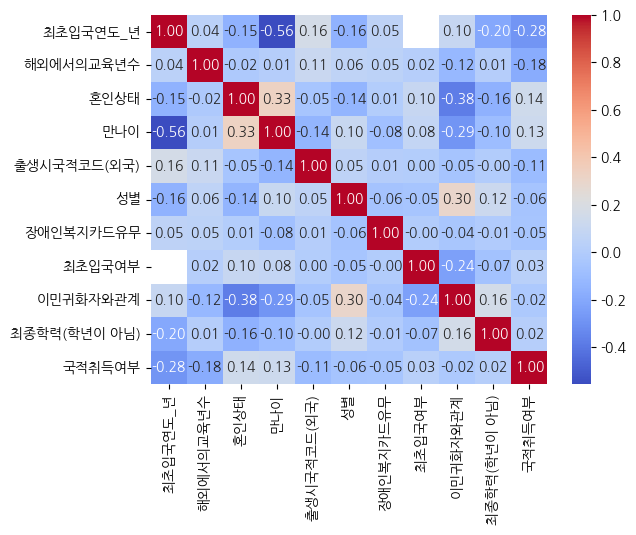

In [12]:
one = pd.read_csv(url+"귀화예측_상위10컬럼.csv")
sns.heatmap(one.corr(),
            annot=True,
            fmt=".2f",
            cmap="coolwarm")
plt.show()

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [14]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [15]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [23]:
from sklearn.neighbors import KNeighborsClassifier

kn= KNeighborsClassifier()
kn.fit(X_train ,y_train)

print(kn.score(X_train,y_train))
print(kn.score(X_test,y_test))
#0.835 , 0.741 로 과적합


0.835494214415168
0.741287984388068


In [24]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
grid = GridSearchCV(
    pipe,
    {"kneighborsclassifier__n_neighbors": [5, 15, 31, 51, 101],
     "kneighborsclassifier__weights": ["uniform", "distance"]},
    cv=5, scoring="roc_auc")
grid.fit(X_train, y_train)

print(grid.best_params_)
from sklearn.metrics import classification_report
print(classification_report(y_test, grid.predict(X_test)))

print(grid.score(X_train,y_train))
print(grid.score(X_test,y_test))
#훈련데이터점수 증가량보다 테스트데이터 점수증가량이 높아 과적합이 완화됨

{'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'uniform'}
              precision    recall  f1-score   support

         0.0       0.76      0.69      0.73      1695
         1.0       0.75      0.80      0.77      1892

    accuracy                           0.75      3587
   macro avg       0.75      0.75      0.75      3587
weighted avg       0.75      0.75      0.75      3587

0.8853301230445222
0.8373965524768159


In [16]:
pred = model.predict(X_test)                     # 0 또는 1로 예측
prob = model.predict_proba(X_test)[:, 1]
print(pred)
print(prob)                                  # 정확도
print(round(accuracy_score(y_test, pred),2)) # 정확도 평균

[1. 1. 0. ... 0. 0. 1.]
[0.6517123  0.81508173 0.49693344 ... 0.284702   0.38386909 0.6989762 ]
0.76


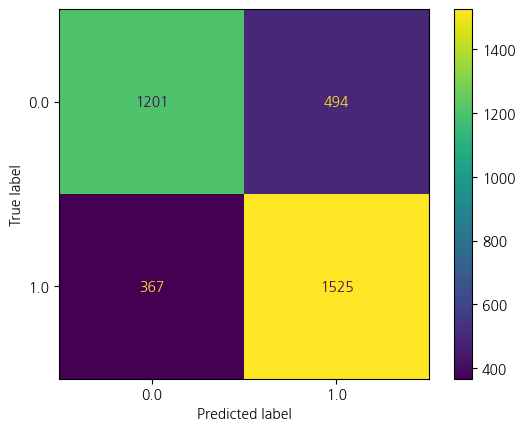

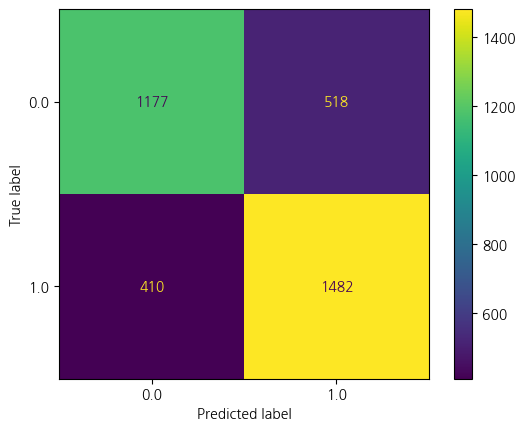

In [20]:
ConfusionMatrixDisplay.from_predictions(y_test, predk)
plt.show()